This is the code of our **ADMM DIP-TV** described in the paper:

https://arxiv.org/abs/2009.11380

This is the version with a uniform weight, that is without the weighted TV.
- Select `name` below to switch between the images.
- Change the `weight`depending on the noise.


# Import libs

In [1]:
from __future__ import print_function
import matplotlib.pyplot as plt
%matplotlib inline

import os

import numpy as np
import random
from models import *

import torch
import torch.optim

from skimage.metrics import peak_signal_noise_ratio as compare_psnr
from utils.denoising_utils import *
from utils.utils import *

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark =True
dtype = torch.cuda.FloatTensor

imsize = -1
PLOT = True
sigma = 20 #25
sigma_ = sigma/255.

In [2]:
import numpy as np
if not hasattr(np, 'alltrue'):
    np.alltrue = np.all

In [3]:
name = 'box'
# name = 'mofang'
# name = 'tuang'
# name = 'clothes'

fname = f"data2/%s/blurrgb.png"%(name)

In [4]:
# from PIL import Image
# import numpy as np

# # 1. 读取图片（自动处理单通道灰度图）
# img = Image.open(fname).convert('L')  # convert('L')确保是单通道灰度图
# # 2. 转为numpy数组并扩展为三通道 (H,W) → (H,W,3)
# img_np = np.array(img)
# img_3c = np.stack([img_np]*3, axis=-1)  # 复制3次通道，生成RGB格式灰度图
# # 3. 保存三通道图片
# Image.fromarray(img_3c).save(f"data2/%s/blurrgb.png"%(name))

# Load event

In [5]:
def ediJ(event, c, idx=None):
        '''
        input:
            x: [B, C, H, W]
            event: [B, T, H, W]
        '''
        left = -torch.cumsum(event[:, :idx].flip(dims=[1]), 1) * c
        right = torch.cumsum(event[:, idx:], 1) * c
        E = torch.cat([torch.exp(left), torch.exp(right)], dim=1).sum(dim=1, keepdim=True) / 12

        return E

In [6]:
# 读取事件数据
c = 0.3
path = f'data2\%s\processed.npy'%(name)
x = np.load(path, allow_pickle=True).item() # .item() 方法将加载的数组转换为 Python 字典
event = torch.from_numpy(x['e1']).unsqueeze(0)
img = x['blur1']
A = ediJ(event, c, idx=6)
A_squeezed = A.squeeze(0)  
A_squeezed = A_squeezed.repeat(3, 1, 1)
A_np = A_squeezed.numpy()

A_pil = np_to_pil(A_np)          # 1. 转成 PIL 图像
A_pil_cropped = crop_image(A_pil, d=32) # 2. 用同样的参数裁剪
A_ref = pil_to_np(A_pil_cropped)  # 3. 转回 numpy


<>:3: SyntaxWarning: invalid escape sequence '\%'
<>:3: SyntaxWarning: invalid escape sequence '\%'
C:\Users\m1501\AppData\Local\Temp\ipykernel_49264\817550418.py:3: SyntaxWarning: invalid escape sequence '\%'
  path = f'data2\%s\processed.npy'%(name)


# Load image

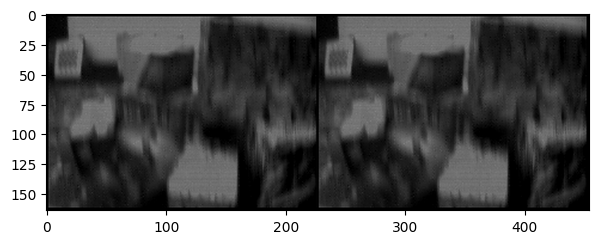

(3, 160, 224)


In [7]:
# Add synthetic noise
img_pil = crop_image(get_image(fname, imsize)[0], d=32)
img_np = pil_to_np(img_pil)  
    
# pay attention!
if img_np.shape[0]==2:
  img_np_temp = np.zeros((3,img_np.shape[1], img_np.shape[2]))
  img_np_temp[0,:,:] = img_np[0,:,:]  
  img_np_temp[1,:,:] = img_np[0,:,:]
  img_np_temp[2,:,:] = img_np[0,:,:]
  img_np = img_np_temp
if img_np.shape[0]==4:
  img_np = img_np[:-1,:,:]
    
img_noisy_pil, img_noisy_np = get_noisy_image(img_np, sigma_)

img_noisy_np = img_np

if PLOT:
    plot_image_grid([img_np, img_noisy_np], 4, 5);

print(img_np.shape)

# Setup

In [8]:
INPUT = 'noise' 
pad = 'reflection'
OPT_OVER = 'net' 

reg_noise_std = 1./30 

show_every = 5

# num_iter = 2400
input_depth = 3 
figsize = 1 
    
    
net = get_net(input_depth, 'skip', pad,
              skip_n33d=128, 
              skip_n33u=128, 
              skip_n11=4, 
              num_scales=5,
              upsample_mode='bilinear').type(dtype)
# net = skip(
#             input_depth, 3, 
#             num_channels_down = [8, 16, 32, 64, 128], 
#             num_channels_up   = [8, 16, 32, 64, 128],
#             num_channels_skip = [0, 0, 0, 4, 4], 
#             upsample_mode='bilinear',
#             need_sigmoid=True, need_bias=True, pad=pad, act_fun='LeakyReLU')

    
net_input = get_noise(input_depth, INPUT, (img_pil.size[1], img_pil.size[0])).type(dtype).detach()

# Compute number of parameters
s  = sum([np.prod(list(p.size())) for p in net.parameters()]); 
print ('Number of params: %d' % s)

# Loss
mse = torch.nn.MSELoss().type(dtype)


Number of params: 2184307


In [9]:
size = img_np.shape
h = size[-2]
w = size[-1]
Dh_psf = np.array([ [0, 0, 0], [1, -1, 0], [0, 0, 0]])
Dv_psf = np.array([ [0, 1, 0], [0, -1, 0], [0, 0, 0]])
Id_psf = np.array([[1]])

Id_DFT = torch.from_numpy(psf2otf(Id_psf, [h,w])).cuda()
Dh_DFT = torch.from_numpy(psf2otf(Dh_psf, [h,w])).cuda()
Dv_DFT = torch.from_numpy(psf2otf(Dv_psf, [h,w])).cuda()

DhT_DFT = torch.conj(Dh_DFT)
DvT_DFT = torch.conj(Dv_DFT)

In [10]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 辅助函数（修正差分核、增加数值检查）
# ==========================================
def np_to_torch(img_np):
    """numpy (C, H, W) -> torch (1, C, H, W)"""
    return torch.from_numpy(img_np).unsqueeze(0).float()

def torch_to_np(img_torch):
    """torch (1, C, H, W) -> numpy (C, H, W)"""
    return img_torch.detach().cpu().numpy()[0]

def norm2_loss(x):
    return torch.sum(x**2) / 2

def compare_psnr(img1, img2):
    mse = np.mean((img1 - img2)**2)
    return 10 * np.log10(1.0 / mse) if mse != 0 else float('inf')

def plot_image_grid(imgs, factor=1):
    """输入 imgs 是 numpy (C, H, W) 列表"""
    fig, axes = plt.subplots(1, len(imgs), figsize=(factor * len(imgs), factor))
    if len(imgs) == 1: axes = [axes]
    for ax, img in zip(axes, imgs):
        if img.shape[0] == 1:  # 单通道
            ax.imshow(np.clip(img[0], 0, 1), cmap='gray')
        else:  # 多通道 (C, H, W) -> (H, W, C)
            ax.imshow(np.clip(img.transpose(1, 2, 0), 0, 1))
        ax.axis('off')
    plt.show()

def D(x, Dh_DFT, Dv_DFT):
    """计算 D(x) = [Dh x, Dv x]（傅里叶域，正确实现）"""
    x_fft = torch.fft.fft2(x, dim=(-2, -1))  # 对最后两维（H,W）做 FFT
    Dh_x = torch.real(torch.fft.ifft2(x_fft * Dh_DFT, dim=(-2, -1)))
    Dv_x = torch.real(torch.fft.ifft2(x_fft * Dv_DFT, dim=(-2, -1)))
    return Dh_x, Dv_x

def Dt(z, Dh_DFT, Dv_DFT):
    """计算 D^T z = Dh^T z_h + Dv^T z_v（转置差分，正确实现）"""
    z_h, z_v = z
    z_h_fft = torch.fft.fft2(z_h, dim=(-2, -1))
    z_v_fft = torch.fft.fft2(z_v, dim=(-2, -1))
    # 转置算子的傅里叶核是原核的共轭 conj(Dh_DFT)
    Dt_z_h = torch.real(torch.fft.ifft2(z_h_fft * torch.conj(Dh_DFT), dim=(-2, -1)))
    Dt_z_v = torch.real(torch.fft.ifft2(z_v_fft * torch.conj(Dv_DFT), dim=(-2, -1)))
    return Dt_z_h + Dt_z_v

def cg_solve(matvec_fn, b, x0, max_iter=20, tol=1e-5):#共轭梯度
    x = x0.clone().detach()
    r = b - matvec_fn(x)
    p = r.clone()
    r_norm_sq = torch.sum(r**2)
    for i in range(max_iter):
        if torch.sqrt(r_norm_sq) < tol:
            break
        Hp = matvec_fn(p)
        alpha = r_norm_sq / torch.sum(p * Hp)
        x = x + alpha * p
        r = r - alpha * Hp
        r_norm_sq_new = torch.sum(r**2)
        beta = r_norm_sq_new / r_norm_sq
        p = r + beta * p
        r_norm_sq = r_norm_sq_new
    return x

# ==========================================
# 修正：正确生成傅里叶域差分核（关键！）
# ==========================================
def generate_diff_kernels(H, W, device):
    """
    生成水平/垂直前向差分算子的傅里叶核 Dh_DFT, Dv_DFT
    基于周期性边界条件的频率响应，无维度错误
    """
    # 频率坐标
    kx = torch.fft.fftfreq(W, 1.0, device=device) * 2 * np.pi  # (W,)
    ky = torch.fft.fftfreq(H, 1.0, device=device) * 2 * np.pi  # (H,)
    kx_grid, ky_grid = torch.meshgrid(kx, ky, indexing='xy')  # (H, W)
    
    # 水平前向差分的傅里叶核：exp(-i kx) - 1
    Dh_DFT = torch.exp(-1j * kx_grid) - 1.0
    # 垂直前向差分的傅里叶核：exp(-i ky) - 1
    Dv_DFT = torch.exp(-1j * ky_grid) - 1.0
    
    # 扩展维度以匹配 (1, 1, H, W)
    return Dh_DFT[None, None, :, :], Dv_DFT[None, None, :, :]

In [ ]:
LR = 1e-3
optimizer = torch.optim.Adam(net.parameters(), lr=LR)

In [12]:

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
net = net.to(device)

# Optimize

In [13]:
# (A_torch*out-img_noisy_torch).shape
A_ref.shape
# img_noisy_torch.shape

(3, 160, 224)

<>:3: SyntaxWarning: invalid escape sequence '\%'
<>:3: SyntaxWarning: invalid escape sequence '\%'
C:\Users\m1501\AppData\Local\Temp\ipykernel_49264\2408014683.py:3: SyntaxWarning: invalid escape sequence '\%'
  path = f'data2\%s\processed.npy'%(name)


Iter 0 | out 范围: [0.0127, 0.3709]
Iter 0 | 原始残差: 18.383234, 对偶残差: 12.794466


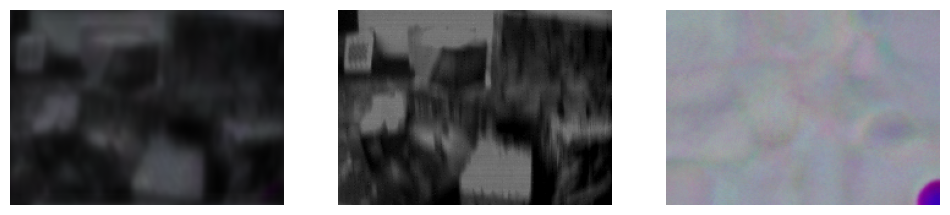

Iter 20 | out 范围: [-0.0047, 0.6430]
Iter 20 | 原始残差: 10.380487, 对偶残差: 5.591518


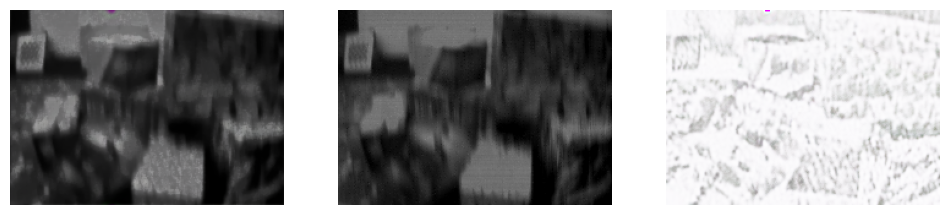

Iter 40 | out 范围: [-0.0011, 0.6748]
Iter 40 | 原始残差: 9.211995, 对偶残差: 2.489131


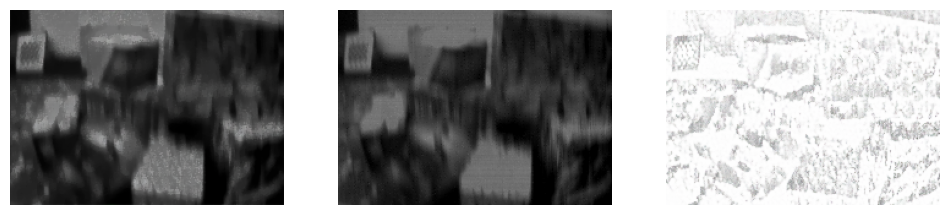

Iter 60 | out 范围: [0.0014, 0.6800]
Iter 60 | 原始残差: 8.673757, 对偶残差: 1.283651


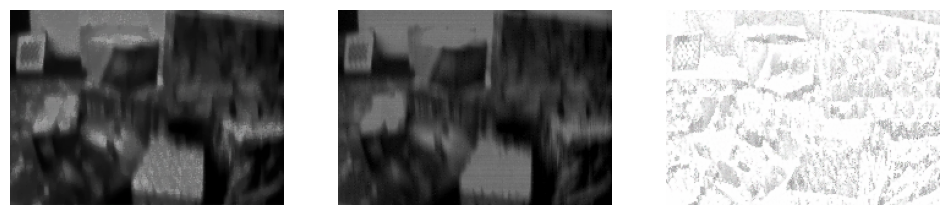

Iter 80 | out 范围: [0.0021, 0.6835]
Iter 80 | 原始残差: 8.581589, 对偶残差: 0.909913


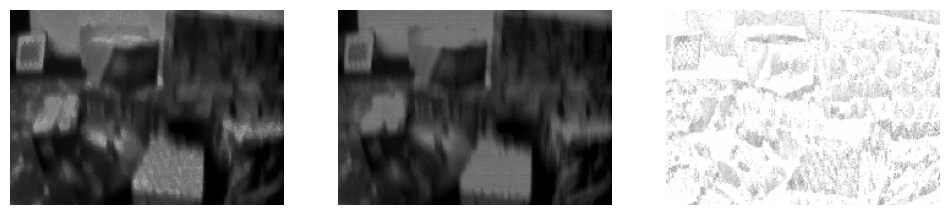

In [ ]:
# c = 0.3
    
# path = f'data2\%s\processed.npy'%(name)
# x = np.load(path, allow_pickle=True).item() # .item() 方法将加载的数组转换为 Python 字典
# event = torch.from_numpy(x['e1']).unsqueeze(0)
# img = x['blur1']
# A = ediJ(event, c, idx=6)
# A_squeezed = A.squeeze(0)  
# A_squeezed = A_squeezed.repeat(3, 1, 1)
# A_np = A_squeezed.numpy()
# A_pil = np_to_pil(A_np)          # 1. 转成 PIL 图像
# A_pil_cropped = crop_image(A_pil, d=32) # 2. 用同样的参数裁剪
# A_np = pil_to_np(A_pil_cropped)  # 3. 转回 numpy


# net = net.to(device)

# # 在这里执行您的代码
# # ==========================================
# # 1. 准备数据（A=全1，增加数值检查）
# # ==========================================
# np.random.seed(42)
# H, W = 128, 128  # 图像尺寸

# # # 生成模拟数据（干净图像 + 噪声）
# # img_np = np.zeros((1, H, W), dtype=np.float32)
# # img_np[0, 30:100, 30:100] = 1.0  # 简单的方块图像，方便观察
# # img_noisy_np = img_np + 0.05 * np.random.randn(1, H, W).astype(np.float32)

# # A 设为全1矩阵
# # A_np = np.ones_like(img_noisy_np)

# # 转换为 torch 张量并设置设备
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# img_noisy_torch = np_to_torch(img_noisy_np).to(device)
# A_torch = np_to_torch(A_np).to(device)
# A_ref = np_to_torch(A_np).to(device)
# A2_torch = A_torch ** 2

# # ==========================================
# # 2. 初始化差分核（调用修正后的函数）
# # ==========================================
# _, C, H, W = img_noisy_torch.shape
# Dh_DFT, Dv_DFT = generate_diff_kernels(H, W, device)

# # ==========================================
# # 3. 初始化变量
# # ==========================================
# t_h = torch.zeros_like(img_noisy_torch, device=device)
# t_v = torch.zeros_like(img_noisy_torch, device=device)
# mu_t_h = torch.zeros_like(img_noisy_torch, device=device)
# mu_t_v = torch.zeros_like(img_noisy_torch, device=device)

# beta_t = 10
# weight = 0.01  # 降低 weight 避免过度平滑
# num_iter = 100
# PLOT = True
# show_every = 20
# inner_iterations = 30

# lambda_l1 = 0.1

# loss_values = []
# psnr_values = []


# # ---------- 收敛性参数初始化 ----------
# eps_pri = 1e-4    # 原始残差容忍阈值
# eps_dual = 1e-4   # 对偶残差容忍阈值
# rho = beta_t      # 对偶残差中的rho参数（通常取beta_t）
# converged = False # 收敛标志
# out = img_noisy_torch.clone()  # 初始化out变量
# t_h_prev = t_h.clone()         # 保存上一轮的t_h
# t_v_prev = t_v.clone()         # 保存上一轮的t_v

# # ==========================================
# # 4. 主循环（增加数值范围打印，调试用）
# # ==========================================
# for i in range(num_iter):

#     if inner_iterations > 1:
#         optimizer = torch.optim.Adam(net.parameters(), lr=LR)

#     for j in range(inner_iterations):
#         optimizer.zero_grad()
        
#         #First problem
#         A_torch = net(net_input)
#         # [Dh_A, Dv_A] = D(A_torch, Dh_DFT, Dv_DFT)

#         total_loss = norm2_loss(A_torch-A_ref)
#         # total_loss += norm2_loss(A_torch*out.detach()-img_noisy_torch)
#         # total_loss += lambda_l1 * torch.norm(A_torch, p=1)
#         # total_loss += (lambda_l1/2)*norm2_loss(Dh_A.detach()) + (lambda_l1/2)*norm2_loss(Dv_A.detach())
        
#         total_loss.backward()
#         optimizer.step()
      
#     running_loss = total_loss.item()
#     loss_values.append(running_loss)

#     A_torch = net(net_input)
    
#     if converged:
#         print(f"算法在第 {i} 次迭代收敛！")
#         break
    
#     # 求解x-子问题
#     # ---------- 1. 构造右端项 b ----------
#     Dt_mu = Dt((t_h - mu_t_h, t_v - mu_t_v), Dh_DFT, Dv_DFT)
#     b = A_torch * img_noisy_torch + beta_t * Dt_mu
    
#     # ---------- 2. 定义矩阵向量乘积 H(z) ----------
#     def matvec(z):
#         term1 = A2_torch * z
#         Dh_z, Dv_z = D(z, Dh_DFT, Dv_DFT)
#         term2 = beta_t * Dt((Dh_z, Dv_z), Dh_DFT, Dv_DFT)
#         return term1 + term2
    
#     # ---------- 3. CG 求解 x ----------
#     x0 = out.clone().detach() if i > 0 else img_noisy_torch.clone()  # 初始值用含噪图像（更好）
#     out = cg_solve(matvec, b, x0, max_iter=15, tol=1e-4)
    
#     # ---------- 调试：打印 out 的数值范围（确保不是全0或全黑） ----------
#     if i % show_every == 0:
#         out_min = out.min().item()
#         out_max = out.max().item()
#         print(f'Iter {i} | out 范围: [{out_min:.4f}, {out_max:.4f}]')
    
#     # ---------- 4. t-子问题：软阈值 ----------
#     Dh_out, Dv_out = D(out, Dh_DFT, Dv_DFT)
#     q_h = Dh_out + mu_t_h
#     q_v = Dv_out + mu_t_v
#     q_norm = torch.sqrt(q_h**2 + q_v**2)
#     q_norm[q_norm == 0] = weight / beta_t
#     q_norm = torch.clamp(q_norm - weight / beta_t, min=0) / q_norm
#     t_h_new = (q_norm * q_h).detach().clone()
#     t_v_new = (q_norm * q_v).detach().clone()
    
#     # ---------- 5. 对偶变量更新 ----------
#     mu_t_h = (mu_t_h + Dh_out - t_h).detach().clone()
#     mu_t_v = (mu_t_v + Dv_out - t_v).detach().clone()
    
#     # ---------- 计算原始残差和对偶残差 ----------
#     Ax = A_torch * out
#     residual_pri = Ax - b + beta_t * Dt((t_h_new - mu_t_h, t_v_new - mu_t_v), Dh_DFT, Dv_DFT)
#     r_norm = torch.norm(residual_pri)
    
#     delta_t_h = t_h_new - t_h_prev
#     delta_t_v = t_v_new - t_v_prev
#     s = rho * Dt((delta_t_h, delta_t_v), Dh_DFT, Dv_DFT)
#     s_norm = torch.norm(s)
    
#     # 打印残差信息
#     if i % show_every == 0:
#         print(f'Iter {i} | 原始残差: {r_norm:.6f}, 对偶残差: {s_norm:.6f}')
#     # 检查收敛条件
#     if r_norm <= eps_pri and s_norm <= eps_dual:
#         converged = True    
    
#     # 更新t的历史值
#     t_h_prev = t_h_new.clone()
#     t_v_prev = t_v_new.clone()
#     t_h = t_h_new
#     t_v = t_v_new
    
#     # ---------- 6. 记录与绘图 ----------
#     out_np = torch_to_np(out)
    
#     if PLOT and i % show_every == 0:
#         plot_image_grid([np.clip(out_np, 0, 1), img_np, np.clip(A_torch.detach().cpu().numpy().squeeze() ,0,1)], factor=4)



In [15]:
import cv2
# 转换为8位无符号整数格式（0-255）
out_uint8 = (np.clip(out_np[0], 0, 1) * 255).astype(np.uint8)
cv2.imwrite(f'results/%s/{weight}_{c}_Ourplus.png'%(name), out_uint8)
print(weight)

0.01


In [16]:
# c = 0.3
    
# path = f'data2\%s\processed.npy'%(name)
# x = np.load(path, allow_pickle=True).item() # .item() 方法将加载的数组转换为 Python 字典
# event = torch.from_numpy(x['e1']).unsqueeze(0)
# img = x['blur1']
# A = ediJ(event, c, idx=6)
# A_squeezed = A.squeeze(0)  
# A_squeezed = A_squeezed.repeat(3, 1, 1)
# A_np = A_squeezed.numpy()


# # 在这里执行您的代码
# # ==========================================
# # 1. 准备数据（A=全1，增加数值检查）
# # ==========================================
# np.random.seed(42)
# H, W = 128, 128  # 图像尺寸

# # # 生成模拟数据（干净图像 + 噪声）
# # img_np = np.zeros((1, H, W), dtype=np.float32)
# # img_np[0, 30:100, 30:100] = 1.0  # 简单的方块图像，方便观察
# # img_noisy_np = img_np + 0.05 * np.random.randn(1, H, W).astype(np.float32)

# # A 设为全1矩阵
# # A_np = np.ones_like(img_noisy_np)

# # 转换为 torch 张量并设置设备
# device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# img_noisy_torch = np_to_torch(img_noisy_np).to(device)
# A_torch = np_to_torch(A_np).to(device)
# A2_torch = A_torch ** 2

# # ==========================================
# # 2. 初始化差分核（调用修正后的函数）
# # ==========================================
# _, C, H, W = img_noisy_torch.shape
# Dh_DFT, Dv_DFT = generate_diff_kernels(H, W, device)

# # ==========================================
# # 3. 初始化变量
# # ==========================================
# t_h = torch.zeros_like(img_noisy_torch, device=device)
# t_v = torch.zeros_like(img_noisy_torch, device=device)
# mu_t_h = torch.zeros_like(img_noisy_torch, device=device)
# mu_t_v = torch.zeros_like(img_noisy_torch, device=device)

# beta_t = 10
# weight = 0.03  # 降低 weight 避免过度平滑
# num_iter = 100
# PLOT = True
# show_every = 20

# loss_values = []
# psnr_values = []

# # ==========================================
# # 4. 主循环（增加数值范围打印，调试用）
# # ==========================================
# for i in range(num_iter):
#     # 求解x-子问题
#     # ---------- 1. 构造右端项 b ----------
#     Dt_mu = Dt((t_h - mu_t_h, t_v - mu_t_v), Dh_DFT, Dv_DFT)
#     b = A_torch * img_noisy_torch + beta_t * Dt_mu
    
#     # ---------- 2. 定义矩阵向量乘积 H(z) ----------
#     def matvec(z):
#         term1 = A2_torch * z
#         Dh_z, Dv_z = D(z, Dh_DFT, Dv_DFT)
#         term2 = beta_t * Dt((Dh_z, Dv_z), Dh_DFT, Dv_DFT)
#         return term1 + term2
    
#     # ---------- 3. CG 求解 x ----------
#     x0 = out.clone().detach() if i > 0 else img_noisy_torch.clone()  # 初始值用含噪图像（更好）
#     out = cg_solve(matvec, b, x0, max_iter=15, tol=1e-4)
    
#     # ---------- 调试：打印 out 的数值范围（确保不是全0或全黑） ----------
#     if i % show_every == 0:
#         out_min = out.min().item()
#         out_max = out.max().item()
#         print(f'Iter {i} | out 范围: [{out_min:.4f}, {out_max:.4f}]')
    
#     # ---------- 4. t-子问题：软阈值 ----------
#     Dh_out, Dv_out = D(out, Dh_DFT, Dv_DFT)
#     q_h = Dh_out + mu_t_h
#     q_v = Dv_out + mu_t_v
#     q_norm = torch.sqrt(q_h**2 + q_v**2)
#     q_norm[q_norm == 0] = weight / beta_t
#     q_norm = torch.clamp(q_norm - weight / beta_t, min=0) / q_norm
#     t_h = (q_norm * q_h).detach().clone()
#     t_v = (q_norm * q_v).detach().clone()
    
#     # ---------- 5. 对偶变量更新 ----------
#     mu_t_h = (mu_t_h + Dh_out - t_h).detach().clone()
#     mu_t_v = (mu_t_v + Dv_out - t_v).detach().clone()
    
#     # ---------- 6. 记录与绘图 ----------
#     out_np = torch_to_np(out)
    
#     # if PLOT and i % show_every == 0:
#     #     plot_image_grid([np.clip(out_np, 0, 1), img_np], factor=4)

# import cv2
# # 转换为8位无符号整数格式（0-255）
# out_uint8 = (np.clip(out_np[0], 0, 1) * 255).astype(np.uint8)
# cv2.imwrite(f'results/%s/{weight}_{c}_Our.png'%(name), out_uint8)
# print(weight)

In [17]:

# # 循环c从0.3到0.9，步长0.1
# for c in [i/10 for i in range(3, 10)]:  # 生成 [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
#     for weight in [0.005, 0.01, 0.05, 0.1]:
         
#         path = f'data2\%s\processed.npy'%(name)
#         x = np.load(path, allow_pickle=True).item() # .item() 方法将加载的数组转换为 Python 字典
#         event = torch.from_numpy(x['e1']).unsqueeze(0)
#         img = x['blur1']
#         A = ediJ(event, c, idx=6)
#         A_squeezed = A.squeeze(0)  
#         A_squeezed = A_squeezed.repeat(3, 1, 1)
#         A_np = A_squeezed.numpy()
        
        
#         # 在这里执行您的代码
#         # ==========================================
#         # 1. 准备数据（A=全1，增加数值检查）
#         # ==========================================
#         np.random.seed(42)
#         H, W = 128, 128  # 图像尺寸

#         # # 生成模拟数据（干净图像 + 噪声）
#         # img_np = np.zeros((1, H, W), dtype=np.float32)
#         # img_np[0, 30:100, 30:100] = 1.0  # 简单的方块图像，方便观察
#         # img_noisy_np = img_np + 0.05 * np.random.randn(1, H, W).astype(np.float32)

#         # A 设为全1矩阵
#         # A_np = np.ones_like(img_noisy_np)

#         # 转换为 torch 张量并设置设备
#         device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#         img_noisy_torch = np_to_torch(img_noisy_np).to(device)
#         A_torch = np_to_torch(A_np).to(device)
#         A2_torch = A_torch ** 2

#         # ==========================================
#         # 2. 初始化差分核（调用修正后的函数）
#         # ==========================================
#         _, C, H, W = img_noisy_torch.shape
#         Dh_DFT, Dv_DFT = generate_diff_kernels(H, W, device)

#         # ==========================================
#         # 3. 初始化变量
#         # ==========================================
#         t_h = torch.zeros_like(img_noisy_torch, device=device)
#         t_v = torch.zeros_like(img_noisy_torch, device=device)
#         mu_t_h = torch.zeros_like(img_noisy_torch, device=device)
#         mu_t_v = torch.zeros_like(img_noisy_torch, device=device)

#         beta_t = 10
#         # weight = 0.005  # 降低 weight 避免过度平滑
#         num_iter = 100
#         PLOT = True
#         show_every = 20

#         loss_values = []
#         psnr_values = []

#         # ==========================================
#         # 4. 主循环（增加数值范围打印，调试用）
#         # ==========================================
#         for i in range(num_iter):
#             # 求解x-子问题
#             # ---------- 1. 构造右端项 b ----------
#             Dt_mu = Dt((t_h - mu_t_h, t_v - mu_t_v), Dh_DFT, Dv_DFT)
#             b = A_torch * img_noisy_torch + beta_t * Dt_mu
            
#             # ---------- 2. 定义矩阵向量乘积 H(z) ----------
#             def matvec(z):
#                 term1 = A2_torch * z
#                 Dh_z, Dv_z = D(z, Dh_DFT, Dv_DFT)
#                 term2 = beta_t * Dt((Dh_z, Dv_z), Dh_DFT, Dv_DFT)
#                 return term1 + term2
            
#             # ---------- 3. CG 求解 x ----------
#             x0 = out.clone().detach() if i > 0 else img_noisy_torch.clone()  # 初始值用含噪图像（更好）
#             out = cg_solve(matvec, b, x0, max_iter=15, tol=1e-4)
            
#             # ---------- 调试：打印 out 的数值范围（确保不是全0或全黑） ----------
#             if i % show_every == 0:
#                 out_min = out.min().item()
#                 out_max = out.max().item()
#                 print(f'Iter {i} | out 范围: [{out_min:.4f}, {out_max:.4f}]')
            
#             # ---------- 4. t-子问题：软阈值 ----------
#             Dh_out, Dv_out = D(out, Dh_DFT, Dv_DFT)
#             q_h = Dh_out + mu_t_h
#             q_v = Dv_out + mu_t_v
#             q_norm = torch.sqrt(q_h**2 + q_v**2)
#             q_norm[q_norm == 0] = weight / beta_t
#             q_norm = torch.clamp(q_norm - weight / beta_t, min=0) / q_norm
#             t_h = (q_norm * q_h).detach().clone()
#             t_v = (q_norm * q_v).detach().clone()
            
#             # ---------- 5. 对偶变量更新 ----------
#             mu_t_h = (mu_t_h + Dh_out - t_h).detach().clone()
#             mu_t_v = (mu_t_v + Dv_out - t_v).detach().clone()
            
#             # ---------- 6. 记录与绘图 ----------
#             out_np = torch_to_np(out)
            
#             # if PLOT and i % show_every == 0:
#             #     plot_image_grid([np.clip(out_np, 0, 1), img_np], factor=4)

#         import cv2
#         # 转换为8位无符号整数格式（0-255）
#         out_uint8 = (np.clip(out_np[0], 0, 1) * 255).astype(np.uint8)
#         cv2.imwrite(f'results/%s/{weight}_{c}_Our.png'%(name), out_uint8)
#         print(weight)

In [18]:
import cv2
# 转换为8位无符号整数格式（0-255）
out_uint8 = (np.clip(out_np[0], 0, 1) * 255).astype(np.uint8)
cv2.imwrite(f'results/%s/{weight}_{c}_Our.png'%(name), out_uint8)

True

# 事件图

In [19]:
# A_torch.shape
im_list = []
A_torch_cpu = (A_torch[:, 0:1, :, :]).detach().cpu() #转cpu

import numpy as np
from pip import main
import torch
import torch.nn as nn
import cv2 as cv
import torch.nn.functional as F
import matplotlib.pyplot as plt
import imageio
import os
from PIL import Image  
c = 0.3
path = f'data2\%s\processed.npy' % (name)
x = np.load(path, allow_pickle=True).item()
im_list = []

for event, img in [(x['e1'], x['blur1'])]:
    event = torch.from_numpy(event).unsqueeze(0)
    img = torch.from_numpy(img).float().unsqueeze(0).unsqueeze(0)
    img = np.zeros_like(img) + 125.
    
    y = A_torch_cpu * img
    
    tmp = y[0, 0].detach().numpy()
    tmp = np.clip(tmp, 0., 255.).astype(np.uint8)
    im_list.append(tmp)
    
plt.figure(figsize=(8, 8))

# 循环显示列表中的图片（如果只有一张，就显示一张）
for idx, img_data in enumerate(im_list):
    plt.subplot(1, len(im_list), idx + 1)
    plt.imshow(img_data, cmap='gray')  # 使用灰度图显示
    plt.title(f'Visualization {idx+1}')
    plt.axis('off') # 关闭坐标轴

plt.tight_layout()
plt.show()
# 2. 在变量定义之后再进行保存操作
# save_path = os.path.join(f'results\%s' % (name), 'event.png')
# Image.fromarray(tmp).save(save_path)
# print(f"已保存：{save_path}")

<>:16: SyntaxWarning: invalid escape sequence '\%'
<>:16: SyntaxWarning: invalid escape sequence '\%'
C:\Users\m1501\AppData\Local\Temp\ipykernel_49264\1847362732.py:16: SyntaxWarning: invalid escape sequence '\%'
  path = f'data2\%s\processed.npy' % (name)
C:\Users\m1501\AppData\Local\Temp\ipykernel_49264\1847362732.py:16: SyntaxWarning: invalid escape sequence '\%'
  path = f'data2\%s\processed.npy' % (name)


ValueError: operands could not be broadcast together with shapes (1,1,160,224) (1,1,180,240) 

<>:12: SyntaxWarning: invalid escape sequence '\%'
<>:12: SyntaxWarning: invalid escape sequence '\%'
C:\Users\m1501\AppData\Local\Temp\ipykernel_53464\3886391794.py:12: SyntaxWarning: invalid escape sequence '\%'
  path = f'data2\%s\processed.npy' % (name)
C:\Users\m1501\AppData\Local\Temp\ipykernel_53464\3886391794.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  y = ediJ(event, c, idx=6) * img


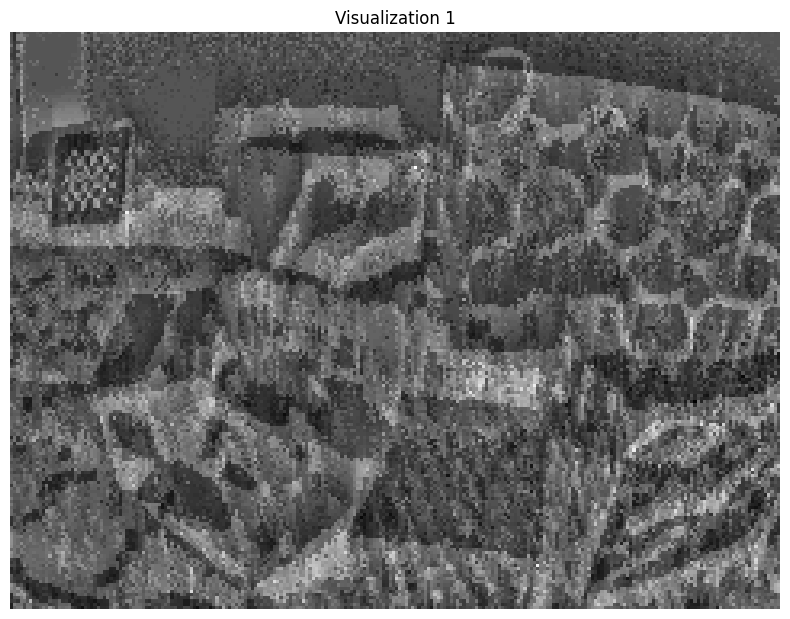

In [ ]:
import numpy as np
from pip import main
import torch
import torch.nn as nn
import cv2 as cv
import torch.nn.functional as F
import matplotlib.pyplot as plt
import imageio
import os
from PIL import Image  
c = 0.3
path = f'data2\%s\processed.npy' % (name)
x = np.load(path, allow_pickle=True).item()
im_list = []

for event, img in [(x['e1'], x['blur1'])]:
    event = torch.from_numpy(event).unsqueeze(0)
    img = torch.from_numpy(img).float().unsqueeze(0).unsqueeze(0)
    img = np.zeros_like(img) + 125.
    
    y = ediJ(event, c, idx=6) * img
    
    tmp = y[0, 0].detach().numpy()
    tmp = np.clip(tmp, 0., 255.).astype(np.uint8)
    im_list.append(tmp)
    
plt.figure(figsize=(8, 8))

# 循环显示列表中的图片（如果只有一张，就显示一张）
for idx, img_data in enumerate(im_list):
    plt.subplot(1, len(im_list), idx + 1)
    plt.imshow(img_data, cmap='gray')  # 使用灰度图显示
    plt.title(f'Visualization {idx+1}')
    plt.axis('off') # 关闭坐标轴

plt.tight_layout()
plt.show()
# 2. 在变量定义之后再进行保存操作
# save_path = os.path.join(f'results\%s' % (name), 'event.png')
# Image.fromarray(tmp).save(save_path)
# print(f"已保存：{save_path}")